In [1]:
# Cell 1: Environment Installation & Configuration
!pip install -q flwr[simulation] datasets transformers peft bitsandbytes accelerate torch
!pip install -q trl evaluate rouge_score codebleu
!pip install -q "tree-sitter>=0.22.0,<0.23.0" tree-sitter-python

import os
import torch

os.environ["RAY_DEDUP_LOGS"] = "1" 

NUM_CLIENTS = 10                  
NUM_ROUNDS = 3                    
LOCAL_EPOCHS = 1                  

MODEL_NAME = "unsloth/Qwen2.5-Coder-0.5B-Instruct"

print(f"✅ Environment configured. Target Base Model: {MODEL_NAME}")
print(f"🚀 Simulation Scale: {NUM_CLIENTS} Virtual Nodes across {NUM_ROUNDS} Global Rounds.")

✅ Environment configured. Target Base Model: unsloth/Qwen2.5-Coder-0.5B-Instruct
🚀 Simulation Scale: 10 Virtual Nodes across 3 Global Rounds.


In [2]:
# Cell 2: True Non-I.I.D. & Dynamic Partitioning Engine
from datasets import load_dataset, Dataset, concatenate_datasets
from transformers import AutoTokenizer

print("🛸 Fetching full security dataset from Hugging Face...")
raw_dataset = load_dataset("StonyBrookNLP/DiSCo", data_files="DiSCo_train.csv", split="train")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

print("Creating UNIFIED dataset with Task Types...")
unified_data = []

for row in raw_dataset:
    instruction = str(row.get("Instruction", ""))
    secure_code = str(row.get("Secure Code", ""))
    vuln_code = str(row.get("Vulnerable Code", ""))
    reasoning = str(row.get("Reasoning", ""))

    # Task Type 0: Generation
    gen_convo = [{"role": "user", "content": instruction}, {"role": "assistant", "content": secure_code}]
    gen_text = tokenizer.apply_chat_template(gen_convo, tokenize=False, add_generation_prompt=False)
    unified_data.append({"text": gen_text, "task_type": 0})

    # Task Type 1: Vulnerable Audit
    if vuln_code and reasoning:
        vuln_convo = [{"role": "user", "content": f"Audit this:\n{vuln_code}"}, {"role": "assistant", "content": f"VULNERABLE.\nReasoning: {reasoning}"}]
        vuln_text = tokenizer.apply_chat_template(vuln_convo, tokenize=False, add_generation_prompt=False)
        unified_data.append({"text": vuln_text, "task_type": 1})

    # Task Type 2: Secure Audit
    if secure_code:
        secure_convo = [{"role": "user", "content": f"Audit this:\n{secure_code}"}, {"role": "assistant", "content": "SECURE."}]
        secure_text = tokenizer.apply_chat_template(secure_convo, tokenize=False, add_generation_prompt=False)
        unified_data.append({"text": secure_text, "task_type": 2})

unified_dataset = Dataset.from_list(unified_data)

print("🔀 Splitting dataset by task_type...")
type0 = unified_dataset.filter(lambda x: x["task_type"] == 0) # Gen
type1 = unified_dataset.filter(lambda x: x["task_type"] == 1) # Vuln
type2 = unified_dataset.filter(lambda x: x["task_type"] == 2) # Sec

# --- THE TRUE NON-I.I.D. FIX ---
# Define skew profiles (ratios of Gen : Vuln : Sec)
SKEW_PROFILES = {
    0: [0.80, 0.10, 0.10], # Client 0: The "Generative" Specialist
    1: [0.10, 0.80, 0.10], # Client 1: The "Vulnerability" Analyst
    2: [0.10, 0.10, 0.80], # Client 2: The "Security" Auditor
    3: [0.34, 0.33, 0.33],  # Client 3: The Generalist (Balanced)
    4: [0.80, 0.10, 0.10], # Client 4: The "Generative" Specialist
    5: [0.10, 0.80, 0.10], # Client 5: The "Vulnerability" Analyst
    6: [0.10, 0.10, 0.80], # Client 6: The "Security" Auditor
    7: [0.34, 0.33, 0.33],  # Client 7: The Generalist (Balanced)
    8: [0.80, 0.10, 0.10], # Client 8: The "Generative" Specialist
    9: [0.10, 0.80, 0.10], # Client 9: The "Vulnerability" Analyst
}

TOTAL_RECORDS_PER_CLIENT = 2700

def get_client_data(cid: str, round_num: int = 1):
    client_id_int = int(cid)
    profile = SKEW_PROFILES[client_id_int]
    
    # Calculate exact counts based on the client's persona profile
    num_gen = int(TOTAL_RECORDS_PER_CLIENT * profile[0])
    num_vuln = int(TOTAL_RECORDS_PER_CLIENT * profile[1])
    num_sec = TOTAL_RECORDS_PER_CLIENT - num_gen - num_vuln # Grab remainder
    
    # --- THE DYNAMIC DATA FIX ---
    # Shuffle the base datasets dynamically using the round number and client ID.
    # This guarantees fresh, randomized samples for every client in every round.
    seed_val = 42 + round_num + (client_id_int * 10)
    t0_shuffled = type0.shuffle(seed=seed_val)
    t1_shuffled = type1.shuffle(seed=seed_val)
    t2_shuffled = type2.shuffle(seed=seed_val)
    
    client_dataset = concatenate_datasets([
        t0_shuffled.select(range(num_gen)),
        t1_shuffled.select(range(num_vuln)),
        t2_shuffled.select(range(num_sec)),
    ]).shuffle(seed=42) # Local shuffle to mix tasks before training
    
    tasks = client_dataset['task_type']
    print(f"🔪 Client {cid} (Round {round_num}) received {len(client_dataset)} fresh records. "
          f"Distribution: Gen={tasks.count(0)} | Vuln={tasks.count(1)} | Sec={tasks.count(2)}")

    return client_dataset

print("✅ True Non-I.I.D. & Dynamic Partitioning Engine Ready.")

🛸 Fetching full security dataset from Hugging Face...


Creating UNIFIED dataset with Task Types...
🔀 Splitting dataset by task_type...


Filter:   0%|          | 0/28467 [00:00<?, ? examples/s]

Filter:   0%|          | 0/28467 [00:00<?, ? examples/s]

Filter:   0%|          | 0/28467 [00:00<?, ? examples/s]

✅ True Non-I.I.D. & Dynamic Partitioning Engine Ready.


In [3]:
# Cell 3: The Virtual Client Factory with NLP Metrics (NaN-Safe & Ray-Safe)
import torch
import gc
import math
import numpy as np
import flwr as fl
from transformers import AutoModelForCausalLM, AutoTokenizer, TrainingArguments, Trainer, DataCollatorForLanguageModeling
from peft import LoraConfig, get_peft_model

print("⚙️ Initializing local tokenizer...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

def preprocess_logits_for_metrics(logits, labels):
    if isinstance(logits, tuple):
        logits = logits[0]
    return logits.argmax(dim=-1)

lora_config = LoraConfig(
    r=16, lora_alpha=32,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    lora_dropout=0.05, bias="none", task_type="CAUSAL_LM"
)

class VirtualFedClient(fl.client.NumPyClient):
    def __init__(self, cid):
        self.cid = cid

    def get_parameters(self, config): 
        return []

    def fit(self, parameters, config):
        local_weights = []
        metrics_dict = {"val_loss": 999.0, "val_ppl": 999.0, "val_accuracy": 0.0, "val_bleu": 0.0, "val_rouge": 0.0, "val_exact_match": 0.0, "val_codebleu": 0.0}
        train_len = 0
        
        # --- DYNAMIC DATA INJECTION ---
        current_round = config.get("server_round", 1)
        dataset = get_client_data(self.cid, current_round)
        
        try:
            model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, device_map={"": 0}, trust_remote_code=True, torch_dtype=torch.float16)
            model = get_peft_model(model, lora_config)
            
            if parameters is not None and len(parameters) > 0:
                trainable_keys = [k for k, v in model.named_parameters() if v.requires_grad]
                state_dict = model.state_dict()
                for k, v_ndarray in zip(trainable_keys, parameters):
                    state_dict[k] = torch.tensor(v_ndarray, dtype=state_dict[k].dtype)
                model.load_state_dict(state_dict, strict=False)
            
            split_data = dataset.train_test_split(test_size=0.1, seed=42 + current_round)
            train_set, eval_set = split_data['train'], split_data['test']
            train_len = len(train_set)
            
            def tokenize_function(example):
                return tokenizer(example["text"], truncation=True, max_length=512) 

            train_set = train_set.map(tokenize_function, remove_columns=train_set.column_names)
            eval_set = eval_set.map(tokenize_function, remove_columns=eval_set.column_names)
            data_collator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=False)

            import evaluate
            from codebleu import calc_codebleu
            
            print(f"📥 [Client {self.cid}] Loading NLP metrics locally in VRAM...")
            bleu_metric = evaluate.load("bleu")
            rouge_metric = evaluate.load("rouge")
            em_metric = evaluate.load("exact_match")
            
            def compute_metrics(eval_preds):
                preds, labels = eval_preds
                labels_shifted = labels[:, 1:]
                preds_shifted = preds[:, :-1]
                
                mask = labels_shifted != -100
                accuracy = (preds_shifted[mask] == labels_shifted[mask]).mean()
                
                labels_for_decoding = np.where(mask, labels_shifted, tokenizer.pad_token_id)
                preds_for_decoding = np.where(preds_shifted >= 0, preds_shifted, tokenizer.pad_token_id)
                
                labels_for_decoding = labels_for_decoding.astype(int)
                preds_for_decoding = preds_for_decoding.astype(int)

                decoded_preds = tokenizer.batch_decode(preds_for_decoding, skip_special_tokens=True)
                decoded_labels = tokenizer.batch_decode(labels_for_decoding, skip_special_tokens=True)
                
                decoded_preds = [p.strip() for p in decoded_preds]
                decoded_labels = [l.strip() for l in decoded_labels]
                
                try:
                    rouge_res = rouge_metric.compute(predictions=decoded_preds, references=decoded_labels)
                    bleu_res = bleu_metric.compute(predictions=decoded_preds, references=decoded_labels)
                    em_res = em_metric.compute(predictions=decoded_preds, references=decoded_labels)
                    codebleu_res = calc_codebleu(references=[[l] for l in decoded_labels], predictions=decoded_preds, lang="python")
                    cb_score = codebleu_res.get('codebleu', 0.0)
                except Exception as e:
                    rouge_res, bleu_res, em_res, cb_score = {}, {}, {}, 0.0

                return {
                    "accuracy": float(accuracy),
                    "bleu": float(bleu_res.get("bleu", 0.0)),
                    "rouge": float(rouge_res.get("rougeL", 0.0)),
                    "exact_match": float(em_res.get("exact_match", 0.0)),
                    "codebleu": float(cb_score)
                }

            training_args = TrainingArguments(
                output_dir=f"./results_client_{self.cid}",
                per_device_train_batch_size=1, 
                gradient_accumulation_steps=4,
                per_device_eval_batch_size=1, 
                num_train_epochs=1, 
                learning_rate=5e-5,          
                max_grad_norm=0.3,           
                fp16=True,                   
                eval_strategy="epoch", 
                logging_steps=50, 
                report_to="none",
                gradient_checkpointing=True
            )
            
            trainer = Trainer(
                model=model, train_dataset=train_set, eval_dataset=eval_set,
                args=training_args, data_collator=data_collator,
                compute_metrics=compute_metrics, preprocess_logits_for_metrics=preprocess_logits_for_metrics
            )
            
            print(f"⚡ [Client {self.cid}] Training ({len(train_set)} samples)...")
            trainer.train()
            
            print(f"🧪 [Client {self.cid}] Evaluating ({len(eval_set)} samples)...")
            eval_results = trainer.evaluate()
            
            v_loss = eval_results.get("eval_loss", 999.0)
            
            if math.isnan(v_loss):
                print(f"❌ [Client {self.cid}] WARNING: LOSS IS NaN. Gradients exploded!")
                v_loss = 999.0
                
            metrics_dict["val_loss"] = v_loss
            metrics_dict["val_ppl"] = math.exp(v_loss) if v_loss < 50 else 999.0
            
            for key in ["accuracy", "bleu", "rouge", "exact_match", "codebleu"]:
                metrics_dict[f"val_{key}"] = eval_results.get(f"eval_{key}", 0.0)
            
            print(f"📊 [Client {self.cid}] PPL: {metrics_dict['val_ppl']:.2f} | Acc: {metrics_dict['val_accuracy']:.2%} | CodeBLEU: {metrics_dict['val_codebleu']:.4f}")
            
            local_weights = [p.cpu().detach().numpy() for p in model.parameters() if p.requires_grad]
            
        finally:
            try: del model
            except: pass 
            try: del trainer
            except: pass 
            gc.collect()
            torch.cuda.empty_cache()
            
        return local_weights, train_len, metrics_dict

def client_fn(context: fl.common.Context) -> fl.client.Client:
    cid = context.node_config["partition-id"] if "partition-id" in context.node_config else str(context.node_id)
    return VirtualFedClient(cid).to_client()

def old_client_fn(cid: str) -> fl.client.Client:
    return VirtualFedClient(cid).to_client()

print("🏭 Dynamic Client Factory Built & Patched!")

⚙️ Initializing local tokenizer...
🏭 Dynamic Client Factory Built & Patched!


In [4]:
# Cell 4: The Flower Orchestrator (FedProx Version) 
import torch
import flwr as fl
from flwr.common import parameters_to_ndarrays
from transformers import AutoModelForCausalLM
from peft import get_peft_model

def weighted_average(metrics):
    total_examples = sum([num_examples for num_examples, _ in metrics])
    agg_metrics = {}
    for key in ["val_loss", "val_ppl", "val_accuracy", "val_bleu", "val_rouge", "val_exact_match", "val_codebleu"]:
        agg_metrics[f"global_{key}"] = sum([n * m.get(key, 0.0) for n, m in metrics]) / total_examples
    return agg_metrics

class SavePeftModelStrategy(fl.server.strategy.FedProx):
    def aggregate_fit(self, server_round, results, failures):
        aggregated_parameters, aggregated_metrics = super().aggregate_fit(server_round, results, failures)
        
        if aggregated_parameters is not None and server_round == NUM_ROUNDS:
            try:
                aggregated_ndarrays = parameters_to_ndarrays(aggregated_parameters)
                base_model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, device_map={"": 0}, trust_remote_code=True, torch_dtype=torch.float16)
                peft_model = get_peft_model(base_model, lora_config)
                
                trainable_keys = [k for k, v in peft_model.named_parameters() if v.requires_grad]
                state_dict = peft_model.state_dict()
                for k, v_ndarray in zip(trainable_keys, aggregated_ndarrays):
                    state_dict[k] = torch.tensor(v_ndarray, dtype=state_dict[k].dtype)
                    
                peft_model.load_state_dict(state_dict, strict=False)
                peft_model.save_pretrained("./final_federated_model")
                print(f"✅ SUCCESS: Global model saved!")
                
                del base_model, peft_model
                torch.cuda.empty_cache()
            except Exception as e:
                print(f"❌ FATAL ERROR: {e}")
                
        return aggregated_parameters, aggregated_metrics

# --- INJECTING THE ROUND NUMBER ---
def fit_config(server_round: int):
    return {"server_round": server_round}

strategy = SavePeftModelStrategy(
    fraction_fit=1.0, fraction_evaluate=0.0, min_fit_clients=NUM_CLIENTS, min_available_clients=NUM_CLIENTS,
    proximal_mu=0.01, fit_metrics_aggregation_fn=weighted_average, 
    on_fit_config_fn=fit_config 
)

print("🔥 Igniting Distributed Orchestrator (Multi-GPU Enabled)...")
try:
    simulation_history = fl.simulation.start_simulation(
        client_fn=old_client_fn, 
        num_clients=NUM_CLIENTS,
        client_resources={"num_cpus": 0.5, "num_gpus": 0.25},
        config=fl.server.ServerConfig(num_rounds=NUM_ROUNDS),
        strategy=strategy,
    )
except Exception as e:
    print(f"Simulation startup warning: {e}")

if simulation_history and simulation_history.metrics_distributed_fit:
    m = simulation_history.metrics_distributed_fit
    
    print("\n=======================================================")
    print("🎉 FEDERATED TRAINING COMPLETE")
    print("=======================================================")
    
    final_ppl = m.get("global_val_ppl", [(0, 0.0)])[-1][1]
    final_acc = m.get("global_val_accuracy", [(0, 0.0)])[-1][1]
    final_cb = m.get("global_val_codebleu", [(0, 0.0)])[-1][1]
    
    print(f"🏆 Final Global Perplexity (PPL): {final_ppl:.2f}")
    print(f"🏆 Final Global Accuracy: {final_acc * 100:.2f}%")
    print(f"🏆 Final Global CodeBLEU: {final_cb:.4f}")
    print("=======================================================")

🔥 Igniting Distributed Orchestrator (Multi-GPU Enabled)...


2026-06-14 14:27:47.152793: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1781447267.171359    1299 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1781447267.177519    1299 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1781447267.193480    1299 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781447267.193495    1299 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781447267.193498    1299 computation_placer.cc:177] computation placer alr

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

...

100%|██████████| 270/270 [01:02<00:00,  4.34it/s]
INFO :      aggregate_fit: received 6 results and 4 failures
`torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/jit/_script.py:362: DeprecationWarning: `torch.jit.script_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
INFO :      configure_evaluate: no clients selected, skipping evaluation
INFO :      
INFO :      [SUMMARY]
INFO :      Run finished 3 round(s) in 11375.59s
INFO :      	History (metrics, distributed, fit):
INFO :      	{'global_val_accuracy': [(1, 0.8430892576508835),
INFO :      	                         (2, 0.8491764643087294),
INFO :      	                         (3, 0.8522025292757326)],
INFO :      	 'global_val_bleu': [(1, 0.0), (2, 0.0), (3, 0.0)],
INFO :      	 'global

✅ SUCCESS: Global model saved!

🎉 FEDERATED TRAINING COMPLETE
🏆 Final Global Perplexity (PPL): 1.70
🏆 Final Global Accuracy: 85.22%
🏆 Final Global CodeBLEU: 0.0000


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


🔌 1. Loading the Final Federated Global Model into RAM...


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]


🔍 PART 1: INTERACTIVE AUDIT TESTS

🔄 GENERATION TEST 1
--- MODEL OUTPUT ---
import sqlite3

def get_user_profile(username):
    conn = sqlite3.connect('users.db')
    cursor = conn.cursor()
    
    query = "SELECT * FROM users WHERE username = ?"
    cursor.execute(query, (username,))
    result = cursor.fetchone()
    conn.close()
    
    if result:
        return {'name': result[1], 'email': result[2]}
    else:
        return None

print(get_user_profile('john_doe'))<|im_end|>

🔄 GENERATION TEST 2
--- MODEL OUTPUT ---
import sqlite3

def get_user_profile(username):
    conn = sqlite3.connect('users.db')
    cursor = conn.cursor()
    query = "SELECT * FROM users WHERE username=?"
    cursor.execute(query, (username,))
    result = cursor.fetchone()
    if result:
        return {
            'id': result[0],
            'name': result[1],
            'email': result[2]
        }
    else:
        raise ValueError("User not found")
    conn.close()

print(get_user_profile('admin')

Auditing Code:   0%|          | 1/200 [00:00<02:25,  1.37it/s]

...

Auditing Code: 100%|█████████▉| 199/200 [01:40<00:00,  1.70it/s]

VULNERABLE.
REASONING: THE CODE


Auditing Code: 100%|██████████| 200/200 [01:41<00:00,  1.98it/s]

SECURE.

🏆 FEDERATED MODEL PERFORMANCE 🏆
Accuracy:  0.5000
Precision: 0.5000
Recall:    0.4900
F1-Score:  0.4949



/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


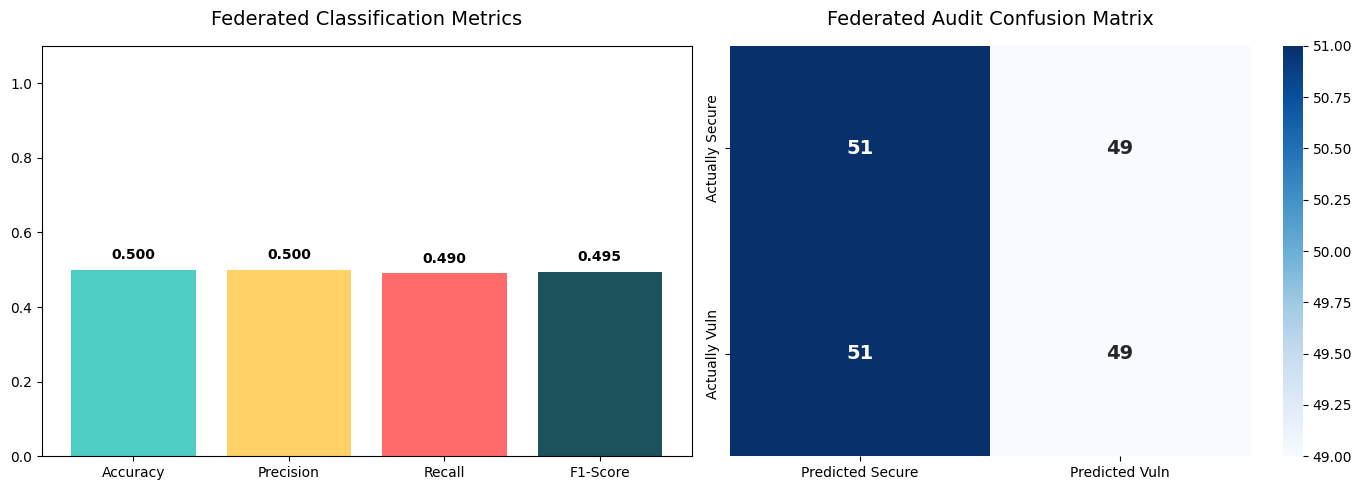

In [5]:
# Cell 5: Global Federated Model Evaluation & Metrics
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from transformers import TextStreamer, AutoModelForCausalLM, AutoTokenizer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from tqdm import tqdm
from peft import PeftModel

print("🔌 1. Loading the Final Federated Global Model into RAM...")
# Load the base model and tokenizer
tokenizer = AutoTokenizer.from_pretrained("unsloth/Qwen2.5-Coder-0.5B-Instruct")
base_model = AutoModelForCausalLM.from_pretrained(
    "unsloth/Qwen2.5-Coder-0.5B-Instruct",
    device_map="auto",
    torch_dtype=torch.float16
)

# Apply the final aggregated LoRA weights from the federated server
# (Update this path to wherever your Flower strategy saved the final model)
model = PeftModel.from_pretrained(base_model, "./final_federated_model")
model.eval()

text_streamer = TextStreamer(tokenizer, skip_prompt=True)

# ==========================================
# PART 1: INTERACTIVE GENERATION & DETECTION
# ==========================================
print("\n=========================================")
print("🔍 PART 1: INTERACTIVE AUDIT TESTS")
print("=========================================")

gen_prompts = [
    "Write a Python function that accepts a username and retrieves the user profile from a SQLite database. Use parameterized queries to prevent SQL injection. Return the profile as a dictionary or None if not found.",
    "Implement a Python function called get_user_profile that connects to users.db, queries the users table by username, and returns the row as a dictionary. Include basic error handling."
] #

for i, prompt in enumerate(gen_prompts, 1):
    print(f"\n🔄 GENERATION TEST {i}")
    messages = [{"role": "user", "content": prompt}]
    formatted_prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer([formatted_prompt], return_tensors="pt").to("cuda")
    
    print("--- MODEL OUTPUT ---")
    with torch.no_grad():
        _ = model.generate(**inputs, streamer=text_streamer, max_new_tokens=200)

# ==========================================
# PART 2: CLASSIFICATION METRICS & MATRICES
# ==========================================
print("\n=========================================")
print("📊 PART 2: SECURITY METRICS ON HOLDOUT SET")
print("=========================================")

# Grab the last 100 rows to create 200 flashcards (100 secure, 100 vulnerable)
holdout_dataset = load_dataset("StonyBrookNLP/DiSCo", data_files="DiSCo_train.csv", split="train[-100:]") #

y_true = []
prompts = []

for row in holdout_dataset:
    if row.get("Vulnerable Code"):
        convo = [{"role": "user", "content": f"Audit this:\n{row['Vulnerable Code']}"}] #
        prompts.append(tokenizer.apply_chat_template(convo, tokenize=False, add_generation_prompt=True))
        y_true.append(1) 
        
    if row.get("Secure Code"):
        convo = [{"role": "user", "content": f"Audit this:\n{row['Secure Code']}"}] #
        prompts.append(tokenizer.apply_chat_template(convo, tokenize=False, add_generation_prompt=True))
        y_true.append(0)

print(f"Auditing {len(prompts)} code snippets using the Federated Model...")
y_pred = []

for prompt in tqdm(prompts, desc="Auditing Code"):
    inputs = tokenizer([prompt], return_tensors="pt").to(model.device)
    with torch.no_grad():
        outputs = model.generate(**inputs, max_new_tokens=10, pad_token_id=tokenizer.eos_token_id)
        
    generated_text = tokenizer.decode(outputs[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip().upper()
    print(generated_text)
    if "VULNERABLE" in generated_text:
        y_pred.append(1)
    else:
        y_pred.append(0)

# Calculate metrics
acc = accuracy_score(y_true, y_pred) #
prec = precision_score(y_true, y_pred, zero_division=0) #
rec = recall_score(y_true, y_pred, zero_division=0) #
f1 = f1_score(y_true, y_pred, zero_division=0) #
cm = confusion_matrix(y_true, y_pred) #

print(f"\n🏆 FEDERATED MODEL PERFORMANCE 🏆")
print(f"Accuracy:  {acc:.4f}\nPrecision: {prec:.4f}\nRecall:    {rec:.4f}\nF1-Score:  {f1:.4f}")

# Generate Figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
bars = ax1.bar(['Accuracy', 'Precision', 'Recall', 'F1-Score'], [acc, prec, rec, f1], color=['#4ECDC4', '#FFD166', '#FF6B6B', '#1A535C'])
ax1.set_title('Federated Classification Metrics', fontsize=14, pad=15)
ax1.set_ylim(0, 1.1)
for bar in bars:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, yval + 0.02, f'{yval:.3f}', ha='center', va='bottom', fontweight='bold')

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax2, 
            xticklabels=['Predicted Secure', 'Predicted Vuln'],
            yticklabels=['Actually Secure', 'Actually Vuln'],
            annot_kws={"size": 14, "weight": "bold"}) #
ax2.set_title('Federated Audit Confusion Matrix', fontsize=14, pad=15)

plt.tight_layout()
plt.show()

In [8]:
!pip install -q "tree-sitter>=0.22.0,<0.23.0" "tree-sitter-python==0.21.0" codebleu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.6/130.6 kB 6.7 MB/s eta 0:00:00


In [10]:
# Cell 5: Real-World Inference & Metric Calculation
import torch
import evaluate
from datasets import load_dataset
from codebleu import calc_codebleu
from transformers import AutoModelForCausalLM, AutoTokenizer
from peft import PeftModel
import warnings
warnings.filterwarnings("ignore")

MODEL_NAME = "unsloth/Qwen2.5-Coder-0.5B-Instruct"
FEDERATED_MODEL_PATH = "./final_federated_model"

print("⚙️ Loading Tokenizer, Base Model, and Federated Weights...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# 1. Load the Base Qwen Model
base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    device_map="auto",
    torch_dtype=torch.float16,
    trust_remote_code=True
)

# 2. Merge your Federated LoRA weights into the Base Model
model = PeftModel.from_pretrained(base_model, FEDERATED_MODEL_PATH)
model.eval() # Set to evaluation mode

# 3. Load Metrics
print("📥 Loading evaluation metrics...")
bleu_metric = evaluate.load("bleu")
rouge_metric = evaluate.load("rouge")
em_metric = evaluate.load("exact_match")

# 4. Prepare Test Data (Let's test on 5 examples from your dataset)
print("📚 Fetching test samples...")
raw_dataset = load_dataset("StonyBrookNLP/DiSCo", data_files="DiSCo_train.csv", split="train")
test_samples = raw_dataset.select(range(1000, 1005)) # Pick 5 random examples

predictions = []
references = []

print("🚀 Starting Autoregressive Generation...")
for i, row in enumerate(test_samples):
    instruction = str(row.get("Instruction", ""))
    secure_code = str(row.get("Secure Code", ""))
    
    if not instruction or not secure_code:
        continue
        
    # We want the model to generate the Secure Code based on the Instruction
    messages = [{"role": "user", "content": instruction}]
    prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    
    # Generate text freely
    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=2000,   # How many tokens it is allowed to write
            temperature=0.2,      # Low temperature for precise coding tasks
            do_sample=True,
            pad_token_id=tokenizer.eos_token_id
        )
    
    # Extract ONLY the newly generated text (ignore the prompt)
    generated_ids = outputs[0][len(inputs.input_ids[0]):]
    generated_text = tokenizer.decode(generated_ids, skip_special_tokens=True).strip()
    
    predictions.append(generated_text)
    references.append(secure_code)
    
    print(f"\n--- Sample {i+1} ---")
    print(f"Generated ({len(generated_text)} chars)...")
    print(generated_text)

# 5. Compute the True NLP Metrics
print("\n📊 ================= FINAL INFERENCE METRICS =================")

# ROUGE
rouge_results = rouge_metric.compute(predictions=predictions, references=references)
print(f"🔹 ROUGE-L:  {rouge_results['rougeL'] * 100:.2f}%")

# BLEU
bleu_results = bleu_metric.compute(predictions=predictions, references=references)
print(f"🔹 BLEU:     {bleu_results['bleu'] * 100:.2f}%")

# Exact Match
em_results = em_metric.compute(predictions=predictions, references=references)
print(f"🔹 Exact Match: {em_results['exact_match'] * 100:.2f}%")

# CodeBLEU (Requires a list of lists for references)
formatted_refs = [[ref] for ref in references]
try:
    codebleu_results = calc_codebleu(references=formatted_refs, predictions=predictions, lang="python")
    print(f"🔹 CodeBLEU: {codebleu_results['codebleu'] * 100:.2f}%")
except Exception as e:
    print(f"🔹 CodeBLEU: Parsing Error (Generated code might have syntax errors)")
    
print("==============================================================")

⚙️ Loading Tokenizer, Base Model, and Federated Weights...


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

📥 Loading evaluation metrics...
📚 Fetching test samples...
🚀 Starting Autoregressive Generation...

--- Sample 1 ---
Generated (583 chars)...
from fastapi import FastAPI, HTTPException
import math

app = FastAPI()

@app.get("/discount")
async def calculate_discount(price: float, discount_percentage: int):
    if not isinstance(price, (int, float)) or not isinstance(discount_percentage, int):
        raise HTTPException(status_code=400, detail="Invalid input type")
    
    discount_amount = price * (discount_percentage / 100)
    discounted_price = price - discount_amount
    return {"discounted_price": discounted_price}

if __name__ == "__main__":
    import uvicorn
    uvicorn.run(app, host="127.0.0.1", port=8000)

--- Sample 2 ---
Generated (261 chars)...
import os

def read_file(file_path):
    if os.path.exists(file_path):
        with open(file_path, 'r') as file:
            return file.read()
    else:
        return "File does not exist."

file_path = "/path/to/missing/file.tx